In [15]:
import os
import glob
import pandas as pd

In [16]:
base_path = "/mnt/c/Users/robbe/Work/Waters_GNN_SmalMol/outputs/adduct_cv/"
all_results = {}

for adduct_folder in os.listdir(base_path):
    adduct_path = os.path.join(base_path, adduct_folder)

    # Skip the cv_results.json file
    if not os.path.isdir(adduct_path):
        continue

    # Convert folder name back to adduct notation
    # MplusHplus -> [M+H]+
    # MminusHminus -> [M-H]-
    # MplusNaplus -> [M+Na]+
    adduct_name = adduct_folder.replace("Mplus", "[M+").replace("Mminus", "[M-")
    adduct_name = adduct_name.replace("plus", "+").replace("minus", "-")
    # Add closing bracket before the final +/-
    if adduct_name.endswith("+") or adduct_name.endswith("-"):
        adduct_name = adduct_name[:-1] + "]" + adduct_name[-1]
    else:
        adduct_name = adduct_name + "]"

    # Get the prediction CSV files
    original_results_path = glob.glob(
        os.path.join(adduct_path, "original", "*_test_predictions.csv")
    )
    baseline_results_path = glob.glob(
        os.path.join(adduct_path, "baseline", "*_test_predictions.csv")
    )

    if not original_results_path or not baseline_results_path:
        print(f"Warning: Missing results for {adduct_name}")
        continue

    # There's only one csv file per folder
    original_df = pd.read_csv(original_results_path[0])
    baseline_df = pd.read_csv(baseline_results_path[0])

    all_results[adduct_name] = {"original": original_df, "baseline": baseline_df}

    print(f"Loaded {adduct_name}: {len(original_df)} samples")

print(f"\nTotal adducts loaded: {len(all_results)}")

Loaded [M-CH3]-: 77 samples
Loaded [M-H]-: 2716 samples
Loaded [M+CH3COO]-: 220 samples
Loaded [M+HCOO]-: 535 samples
Loaded [M+H-H2O]+: 322 samples
Loaded [M+H]+: 5135 samples
Loaded [M+K]+: 209 samples
Loaded [M+Na-2H]-: 262 samples
Loaded [M+Na]+: 2615 samples
Loaded [M+NH4]+: 684 samples

Total adducts loaded: 10


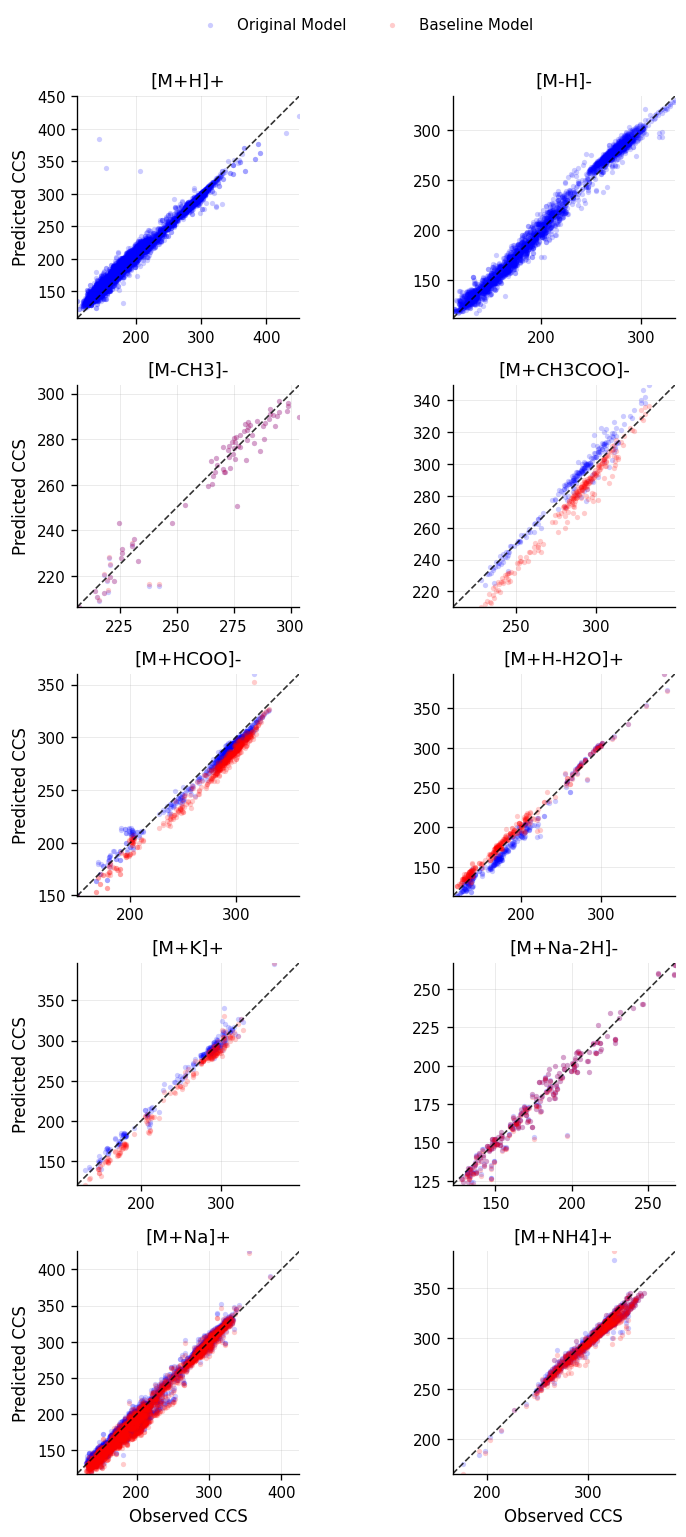

In [17]:
import matplotlib.pyplot as plt

# --- Aesthetics (does not change plotting logic) ---
plt.rcParams.update(
    {
        "figure.dpi": 120,
        "font.size": 10,
        "axes.titlesize": 11,
        "axes.labelsize": 10,
        "xtick.labelsize": 9,
        "ytick.labelsize": 9,
        "legend.fontsize": 9,
        "axes.spines.top": False,
        "axes.spines.right": False,
    }
)

# Reorder adducts to put [M+H]+ and [M-H]- first
adduct_order = ["[M+H]+", "[M-H]-"] + [
    k for k in all_results.keys() if k not in ["[M+H]+", "[M-H]-"]
]

fig, axes = plt.subplots(5, 2, figsize=(8, 14))
axes = axes.flatten()

# Increase vertical spacing (rows), decrease horizontal spacing (columns)
fig.subplots_adjust(hspace=0.3, wspace=0.02, top=0.93)

legend_entries = {}

for i, adduct in enumerate(adduct_order):
    ax = axes[i]
    dfs = all_results[adduct]
    original_df = dfs["original"]
    baseline_df = dfs["baseline"]

    h1 = ax.scatter(
        original_df["CCS"],
        original_df["Predicted CCS"],
        color="blue",
        alpha=0.2,
        s=10,
        linewidths=0,
        rasterized=True,
        label="Original Model",
    )
    legend_entries.setdefault("Original Model", h1)

    plotted_baseline = False
    if not original_df.equals(baseline_df):
        h2 = ax.scatter(
            baseline_df["CCS"],
            baseline_df["Predicted CCS"],
            color="red",
            alpha=0.2,
            s=10,
            linewidths=0,
            rasterized=True,
            label="Baseline Model",
        )
        legend_entries.setdefault("Baseline Model", h2)
        plotted_baseline = True

    ax.set_title(f"{adduct}", pad=6)
    ax.grid(True, which="major", alpha=0.25, linewidth=0.6)
    ax.set_axisbelow(True)

    x_min = original_df["CCS"].min()
    x_max = original_df["CCS"].max()
    if plotted_baseline:
        x_min = min(x_min, baseline_df["CCS"].min())
        x_max = max(x_max, baseline_df["CCS"].max())

    y_min = original_df["Predicted CCS"].min()
    y_max = original_df["Predicted CCS"].max()
    if plotted_baseline:
        y_min = min(y_min, baseline_df["Predicted CCS"].min())
        y_max = max(y_max, baseline_df["Predicted CCS"].max())

    lo = min(x_min, y_min)
    hi = max(x_max, y_max)

    ax.plot([lo, hi], [lo, hi], color="black", linestyle="--", linewidth=1.0, alpha=0.8)
    ax.set_xlim(lo, hi)
    ax.set_ylim(lo, hi)
    ax.set_aspect("equal", adjustable="box")

    if i % 2 == 0:
        ax.set_ylabel("Predicted CCS")
    else:
        ax.set_ylabel("")
    if i >= 8:
        ax.set_xlabel("Observed CCS")
    else:
        ax.set_xlabel("")

for j in range(len(adduct_order), len(axes)):
    axes[j].set_visible(False)

if legend_entries:
    labels_in_order = ["Original Model", "Baseline Model"]
    handles = [legend_entries[l] for l in labels_in_order if l in legend_entries]
    labels = [l for l in labels_in_order if l in legend_entries]
    fig.legend(
        handles,
        labels,
        loc="upper center",
        ncol=len(handles),
        frameon=False,
        bbox_to_anchor=(0.5, 0.985),
    )

plt.show()

In [18]:
graphccs = pd.read_csv("/mnt/c/Users/robbe/Work/Waters_GNN_SmalMol/data/GraphCCS.csv")

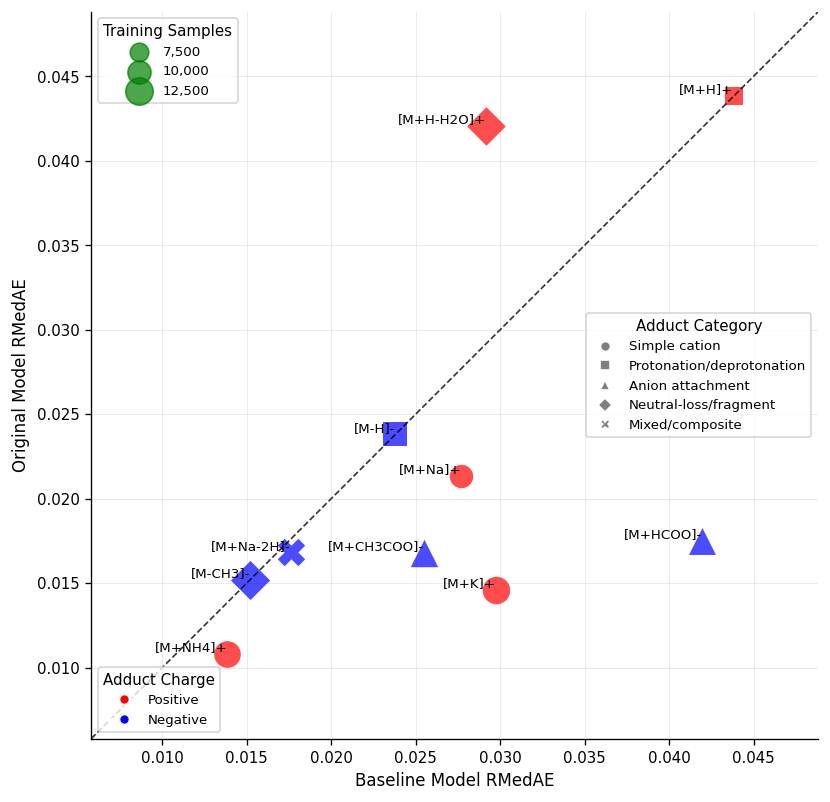

In [22]:
from matplotlib.lines import Line2D

# Define adduct categories
adduct_categories = {
    "Simple cation": ["[M+Na]+", "[M+K]+", "[M+NH4]+"],
    "Protonation/deprotonation": ["[M+H]+", "[M-H]-"],
    "Anion attachment": ["[M+HCOO]-", "[M+CH3COO]-"],
    "Neutral-loss/fragment": ["[M+H-H2O]+", "[M-CH3]-"],
    "Mixed/composite": ["[M+Na-2H]-"],
}

# Create mapping from adduct to category
adduct_to_category = {}
for category, adducts_list in adduct_categories.items():
    for adduct in adducts_list:
        adduct_to_category[adduct] = category

# Define marker shapes for each category
category_markers = {
    "Simple cation": "o",  # circle
    "Protonation/deprotonation": "s",  # square
    "Anion attachment": "^",  # triangle up
    "Neutral-loss/fragment": "D",  # diamond
    "Mixed/composite": "X",  # X
}

# Now plot a scatterplot of on the x-axis the MAE of the baseline model and on the y-axis the MAE of the original model in one scatterplot
fig, ax = plt.subplots(figsize=(7, 7))
mae_original = []
mae_baseline = []
adducts = []
training_sample_counts = []

for adduct in all_results.keys():
    dfs = all_results[adduct]
    original_df = dfs["original"]
    baseline_df = dfs["baseline"]
    mae_orig = original_df["Relative Error"].median()
    mae_base = baseline_df["Relative Error"].median()
    mae_original.append(mae_orig)
    mae_baseline.append(mae_base)
    adducts.append(adduct)

    # Count training samples: all samples in graphccs that don't have this adduct
    training_count = len(graphccs[graphccs["Adduct"] != adduct])
    training_sample_counts.append(training_count)

# Scale point sizes smaller
point_sizes = [(count / 300) ** 1.5 for count in training_sample_counts]

# Determine color based on charge
colors = ["red" if adduct.endswith("+") else "blue" for adduct in adducts]

# Plot each point with its category-specific marker
for i, adduct in enumerate(adducts):
    category = adduct_to_category.get(adduct, "Simple cation")  # default fallback
    marker = category_markers[category]

    ax.scatter(
        mae_baseline[i],
        mae_original[i],
        c=[colors[i]],
        marker=marker,
        alpha=0.7,
        s=point_sizes[i],
        linewidths=0,
        rasterized=True,
    )

for i, adduct in enumerate(adducts):
    ax.text(
        mae_baseline[i],
        mae_original[i],
        adduct,
        fontsize=8,
        ha="right",
        va="bottom",
    )

lo = min(min(mae_baseline), min(mae_original)) - 0.005
hi = max(max(mae_baseline), max(mae_original)) + 0.005
ax.plot([lo, hi], [lo, hi], color="black", linestyle="--", linewidth=1.0, alpha=0.8)
ax.set_xlim(lo, hi)
ax.set_ylim(lo, hi)
ax.set_aspect("equal", adjustable="box")
ax.set_xlabel("Baseline Model RMedAE")
ax.set_ylabel("Original Model RMedAE")
ax.grid(True, which="major", alpha=0.25, linewidth=0.6)
ax.set_axisbelow(True)

# Add size legend with smaller scaling
legend_sizes = [7500, 10000, 12500]
legend_labels = [f"{size:,}" for size in legend_sizes]
legend_points = [(size / 300) ** 1.5 for size in legend_sizes]

legend_handles = [
    plt.scatter([], [], s=size, color="green", alpha=0.7) for size in legend_points
]

size_legend = ax.legend(
    legend_handles,
    legend_labels,
    title="Training Samples",
    loc="upper left",
    frameon=True,
    scatterpoints=1,
    fontsize=8,
    title_fontsize=9,
)

# Add the size legend to the plot first
ax.add_artist(size_legend)

# Charge legend
charge_legend_elements = [
    Line2D(
        [0],
        [0],
        marker="o",
        color="w",
        label="Positive",
        markerfacecolor="red",
        markersize=6,
    ),
    Line2D(
        [0],
        [0],
        marker="o",
        color="w",
        label="Negative",
        markerfacecolor="blue",
        markersize=6,
    ),
]
charge_legend = ax.legend(
    charge_legend_elements,
    [elem.get_label() for elem in charge_legend_elements],
    title="Adduct Charge",
    loc="lower left",
    frameon=True,
    fontsize=8,
    title_fontsize=9,
)

# Add charge legend as artist
ax.add_artist(charge_legend)

# Category legend (marker shapes)
category_legend_elements = [
    Line2D(
        [0],
        [0],
        marker=category_markers["Simple cation"],
        color="w",
        label="Simple cation",
        markerfacecolor="gray",
        markersize=6,
    ),
    Line2D(
        [0],
        [0],
        marker=category_markers["Protonation/deprotonation"],
        color="w",
        label="Protonation/deprotonation",
        markerfacecolor="gray",
        markersize=6,
    ),
    Line2D(
        [0],
        [0],
        marker=category_markers["Anion attachment"],
        color="w",
        label="Anion attachment",
        markerfacecolor="gray",
        markersize=6,
    ),
    Line2D(
        [0],
        [0],
        marker=category_markers["Neutral-loss/fragment"],
        color="w",
        label="Neutral-loss/fragment",
        markerfacecolor="gray",
        markersize=6,
    ),
    Line2D(
        [0],
        [0],
        marker=category_markers["Mixed/composite"],
        color="w",
        label="Mixed/composite",
        markerfacecolor="gray",
        markersize=6,
    ),
]
category_legend = ax.legend(
    category_legend_elements,
    [elem.get_label() for elem in category_legend_elements],
    title="Adduct Category",
    loc="center right",
    frameon=True,
    fontsize=8,
    title_fontsize=9,
)

plt.tight_layout()
plt.show()

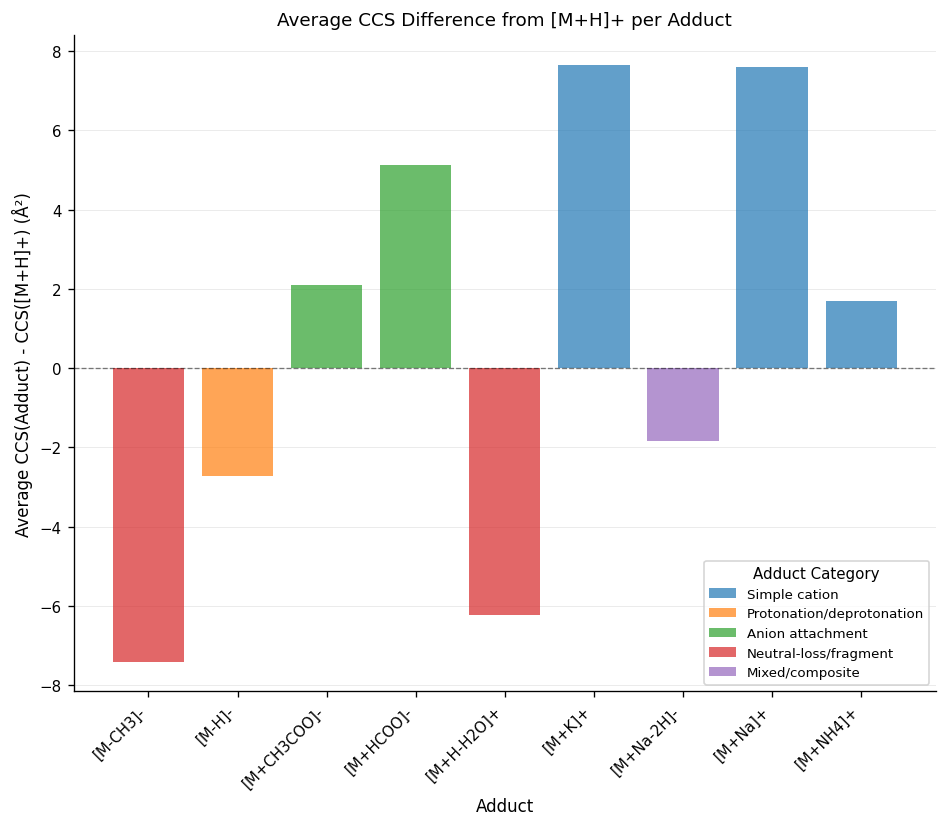

In [20]:
# Evaluate the effects of the adduct on observed CCS values.
# We do this by plotting the average CCS difference between molecules with +H and then with other adducts, for those molecules that have both adducts measured.

# Define colors for each category
category_colors = {
    "Simple cation": "#1f77b4",  # blue
    "Protonation/deprotonation": "#ff7f0e",  # orange
    "Anion attachment": "#2ca02c",  # green
    "Neutral-loss/fragment": "#d62728",  # red
    "Mixed/composite": "#9467bd",  # purple
}

fig, ax = plt.subplots(figsize=(8, 7))
ccs_differences = []
adduct_labels = []
bar_colors = []

for adduct in all_results.keys():
    if adduct == "[M+H]+":
        continue  # Skip the reference adduct

    # Find molecules that have both [M+H]+ and the current adduct
    graphccs_h = graphccs[graphccs["Adduct"] == "[M+H]+"]
    graphccs_other = graphccs[graphccs["Adduct"] == adduct]

    merged = pd.merge(
        graphccs_h,
        graphccs_other,
        on="SMILES",
        suffixes=("_H", "_Other"),
    )

    if merged.empty:
        print(f"No overlapping molecules for {adduct} and [M+H]+")
        continue

    # Calculate average CCS difference
    ccs_diff = (merged["CCS_Other"] - merged["CCS_H"]).mean()
    ccs_differences.append(ccs_diff)
    adduct_labels.append(adduct)

    # Get color based on category
    category = adduct_to_category.get(adduct, "Simple cation")
    bar_colors.append(category_colors[category])

bars = ax.bar(range(len(adduct_labels)), ccs_differences, color=bar_colors, alpha=0.7)
ax.set_ylabel("Average CCS(Adduct) - CCS([M+H]+) (Å²)")
ax.set_xlabel("Adduct")
ax.set_title("Average CCS Difference from [M+H]+ per Adduct")
ax.set_xticks(range(len(adduct_labels)))
ax.set_xticklabels(adduct_labels, rotation=45, ha="right")
ax.axhline(y=0, color="black", linestyle="--", linewidth=0.8, alpha=0.5)
ax.grid(True, axis="y", alpha=0.25, linewidth=0.6)
ax.set_axisbelow(True)

# Add category legend
from matplotlib.patches import Patch

legend_elements = [
    Patch(facecolor=category_colors["Simple cation"], label="Simple cation", alpha=0.7),
    Patch(
        facecolor=category_colors["Protonation/deprotonation"],
        label="Protonation/deprotonation",
        alpha=0.7,
    ),
    Patch(
        facecolor=category_colors["Anion attachment"],
        label="Anion attachment",
        alpha=0.7,
    ),
    Patch(
        facecolor=category_colors["Neutral-loss/fragment"],
        label="Neutral-loss/fragment",
        alpha=0.7,
    ),
    Patch(
        facecolor=category_colors["Mixed/composite"], label="Mixed/composite", alpha=0.7
    ),
]
ax.legend(
    handles=legend_elements,
    title="Adduct Category",
    loc="lower right",
    fontsize=8,
    title_fontsize=9,
)

plt.tight_layout()
plt.show()